# Analiza zbioru COCO 2017

In [ ]:
import json
import os
import random
import re
import sys
import wave
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
from IPython.display import Audio, display
from PIL import Image
from torchvision.transforms import ToTensor
from tqdm.auto import tqdm

sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.dpi"] = 120


In [13]:
PATH_IMAGES_TRAIN = "../data/spokencoco/train2014"
PATH_IMAGES_VAL = "../data/spokencoco/val2014"
PATH_CAPTIONS_TRAIN = "../data/spokencoco/SpokenCOCO_train.json"
PATH_CAPTIONS_VAL = "../data/spokencoco/SpokenCOCO_val.json"
PATH_WAVS_TRAIN = "../data/spokencoco/wavs/train"
PATH_WAVS_VAL = "../data/spokencoco/wavs/val"

with open(PATH_CAPTIONS_TRAIN, "r") as f:
    train_data = json.load(f)

with open(PATH_CAPTIONS_VAL, "r") as f:
    val_data = json.load(f)

print(f"Train - images count: {len(train_data['data'])}")
print(f"Val   - images count: {len(val_data['data'])}")

train_wavs = sum(
    1 for item in train_data["data"]
    for caption in item["captions"] if caption.get("wav")
)
val_wavs = sum(
    1 for item in val_data["data"]
    for caption in item["captions"] if caption.get("wav")
)

print(f"Train - wavs count: {train_wavs}")
print(f"Val   - wavs count: {val_wavs}")


Train - images count: 118287
Val   - images count: 5000
Train - wavs count: 592187
Val   - wavs count: 25035


In [29]:
id_to_file = {
    os.path.basename(item["image"]): item["image"]
    for dataset in (train_data, val_data)
    for item in dataset["data"]
}

images_ids = set(id_to_file.keys())

annotation_dict = {}
for dataset in (train_data, val_data):
    for item in dataset["data"]:
        annotation_dict.setdefault(
            os.path.basename(item["image"]), []
        ).extend(
            caption["text"] for caption in item.get("captions", [])
        )

annotated_ids = set(annotation_dict.keys())

images_names = (
    set(os.listdir(PATH_IMAGES_TRAIN))
    | set(os.listdir(PATH_IMAGES_VAL))
)

train_wavs_paths = {
    caption["wav"]
    for item in train_data["data"]
    for caption in item["captions"]
    if caption.get("wav")
}

val_wavs_paths = {
    caption["wav"]
    for item in val_data["data"]
    for caption in item["captions"]
    if caption.get("wav")
}

## Data Integrity

In [31]:
print(
    "Annotated imgs == All imgs:",
    annotated_ids == images_ids
)

images_names = (
    set(os.listdir(PATH_IMAGES_TRAIN))
    | set(os.listdir(PATH_IMAGES_VAL))
)

missing_on_disk = set(os.path.basename(path) for path in id_to_file.keys()) - images_names
missing_in_json = images_names - set(os.path.basename(path) for path in id_to_file.keys())

print("Img count in JSONs:", len(id_to_file))
print("Img count on disc:", len(images_names))

print("\nIn JSONs but not on disc:", len(missing_on_disk))
print(list(missing_on_disk)[:10])

print("\nOn disc but not in JSONs:", len(missing_in_json))
print(list(missing_in_json)[:10])

def check_wavs(wav_paths, wav_root, name) -> None:  # noqa: ANN001
    wav_root = Path(wav_root)
    missing = []
    for wav in wav_paths:
        relative_path = Path(wav)

        parts = relative_path.parts
        if len(parts) >= 3 and parts[0] == "wavs":
            relative_path = Path(*parts[2:])

        if not (wav_root / relative_path).is_file():
            missing.append(wav)

    print(f"\n{name}:")
    print("WAV paths in JSON:", len(wav_paths))
    print("Existing WAV files:", len(wav_paths) - len(missing))
    print("Missing WAV files:", len(missing))
    print("Missing examples:", missing[:10])

check_wavs(train_wavs_paths, PATH_WAVS_TRAIN, "Train")
check_wavs(val_wavs_paths, PATH_WAVS_VAL, "Val")

Annotated imgs == All imgs: True
Img count in JSONs: 123287
Img count on disc: 123287

In JSONs but not on disc: 0
[]

On disc but not in JSONs: 0
[]

Train:
WAV paths in JSON: 592187
Existing WAV files: 592187
Missing WAV files: 0
Missing examples: []

Val:
WAV paths in JSON: 25035
Existing WAV files: 25035
Missing WAV files: 0
Missing examples: []


## Size and image proportions

In [ ]:
image_records = []

image_records = []

for filename, image_path in id_to_file.items():
    if image_path.startswith("train2014/"):
        full_path = os.path.join(PATH_IMAGES_TRAIN, filename)
    elif image_path.startswith("val2014/"):
        full_path = os.path.join(PATH_IMAGES_VAL, filename)
    else:
        continue

    if os.path.isfile(full_path):
        try:
            with Image.open(full_path) as img:
                width, height = img.size

            image_records.append({
                "image": filename,
                "width": width,
                "height": height,
                "aspect_ratio": width / height
            })
        except (OSError, ValueError):
            continue

images_df = pd.DataFrame(image_records)

Images analyzed: 123287


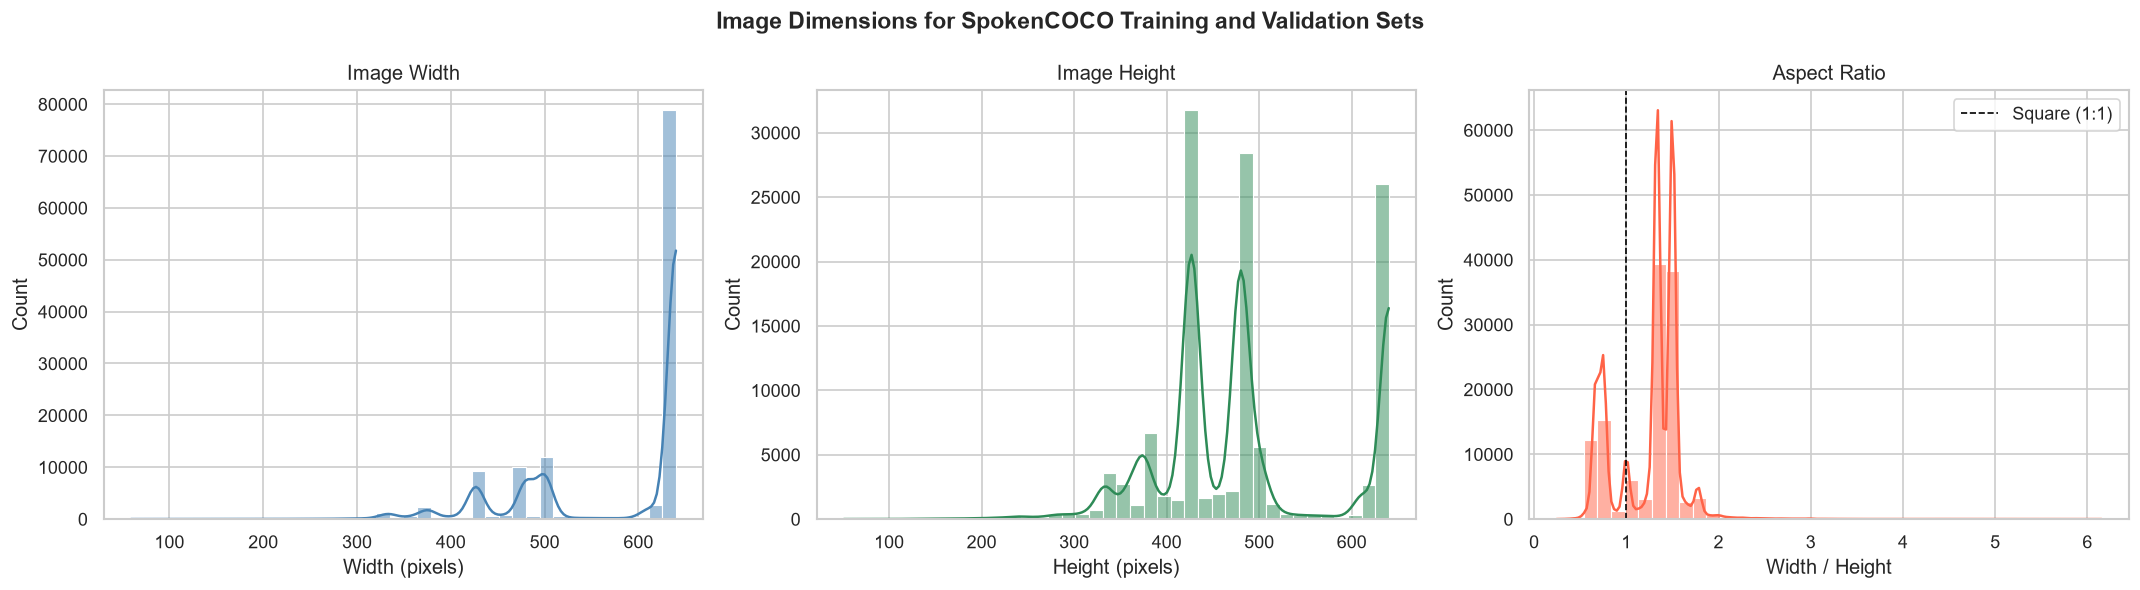

In [34]:
print("Images analyzed:", len(images_df))

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle(
    "Image Dimensions for SpokenCOCO Training and Validation Sets",
    fontsize=14,
    fontweight="bold"
)

sns.histplot(
    images_df["width"], ax=axes[0],
    color="steelblue", kde=True, bins=40
)
axes[0].set_title("Image Width")
axes[0].set_xlabel("Width (pixels)")

sns.histplot(
    images_df["height"], ax=axes[1],
    color="seagreen", kde=True, bins=40
)
axes[1].set_title("Image Height")
axes[1].set_xlabel("Height (pixels)")

sns.histplot(
    images_df["aspect_ratio"], ax=axes[2],
    color="tomato", kde=True, bins=40
)
axes[2].set_title("Aspect Ratio")
axes[2].set_xlabel("Width / Height")
axes[2].axvline(
    1.0, color="black", linestyle="--",
    linewidth=1, label="Square (1:1)"
)
axes[2].legend()

plt.tight_layout()
plt.show()

## Text caption statistics

In [35]:
captions = [
    caption["text"]
    for dataset in (train_data, val_data)
    for item in dataset["data"]
    for caption in item.get("captions", [])
]

word_counts = [len(caption.split()) for caption in captions]
char_counts = [len(caption) for caption in captions]

stats_df = pd.DataFrame({
    "word_count": word_counts,
    "char_count": char_counts
})

print(stats_df.describe().round(2))

       word_count  char_count
count   617222.00   617222.00
mean        10.45       51.47
std          2.39       12.48
min          5.00       20.00
25%          9.00       43.00
50%         10.00       49.00
75%         11.00       57.00
max         49.00      246.00


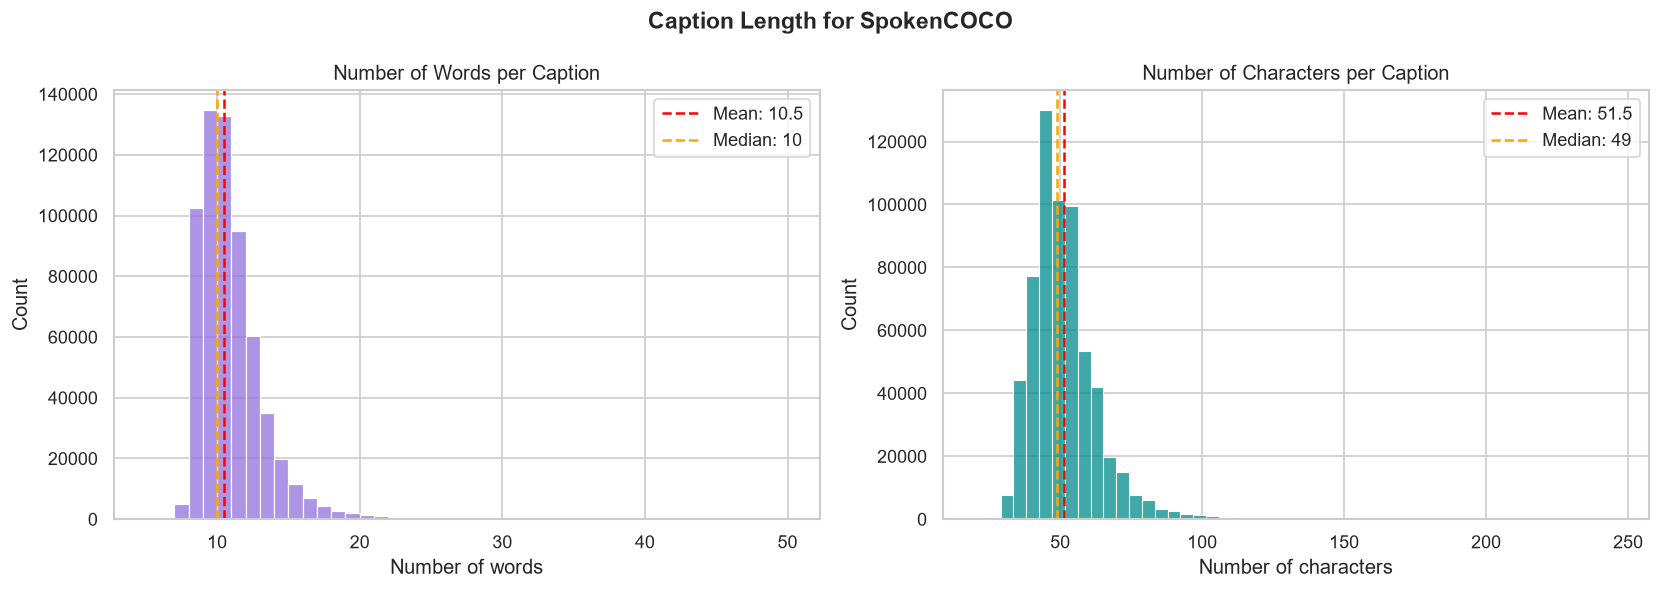

In [36]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle("Caption Length for SpokenCOCO", fontsize=14, fontweight="bold")

bins_w = range(min(word_counts), max(word_counts) + 2)
sns.histplot(word_counts, bins=bins_w, color="mediumpurple", ax=axes[0])
axes[0].set_title("Number of Words per Caption")
axes[0].set_xlabel("Number of words")
axes[0].axvline(
    np.mean(word_counts),
    color="red",
    linestyle="--",
    label=f"Mean: {np.mean(word_counts):.1f}",
)
axes[0].axvline(
    np.median(word_counts),
    color="orange",
    linestyle="--",
    label=f"Median: {np.median(word_counts):.0f}",
)
axes[0].legend()

sns.histplot(char_counts, bins=50, color="darkcyan", ax=axes[1])
axes[1].set_title("Number of Characters per Caption")
axes[1].set_xlabel("Number of characters")
axes[1].axvline(
    np.mean(char_counts),
    color="red",
    linestyle="--",
    label=f"Mean: {np.mean(char_counts):.1f}",
)
axes[1].axvline(
    np.median(char_counts),
    color="orange",
    linestyle="--",
    label=f"Median: {np.median(char_counts):.0f}",
)
axes[1].legend()

plt.tight_layout()
plt.show()

## Amount of captions per image

In [37]:
captions_per_image = Counter(
    len(captions) for captions in annotation_dict.values()
)

print("Distribution of captions per image:")
for n, count in sorted(captions_per_image.items()):
    print(
        f"  {n} caption(s): {count} images "
        f"({100 * count / len(annotation_dict):.1f}%)"
    )

Distribution of captions per image:
  5 caption(s): 122507 images (99.4%)
  6 caption(s): 773 images (0.6%)
  7 caption(s): 7 images (0.0%)


## Most common words

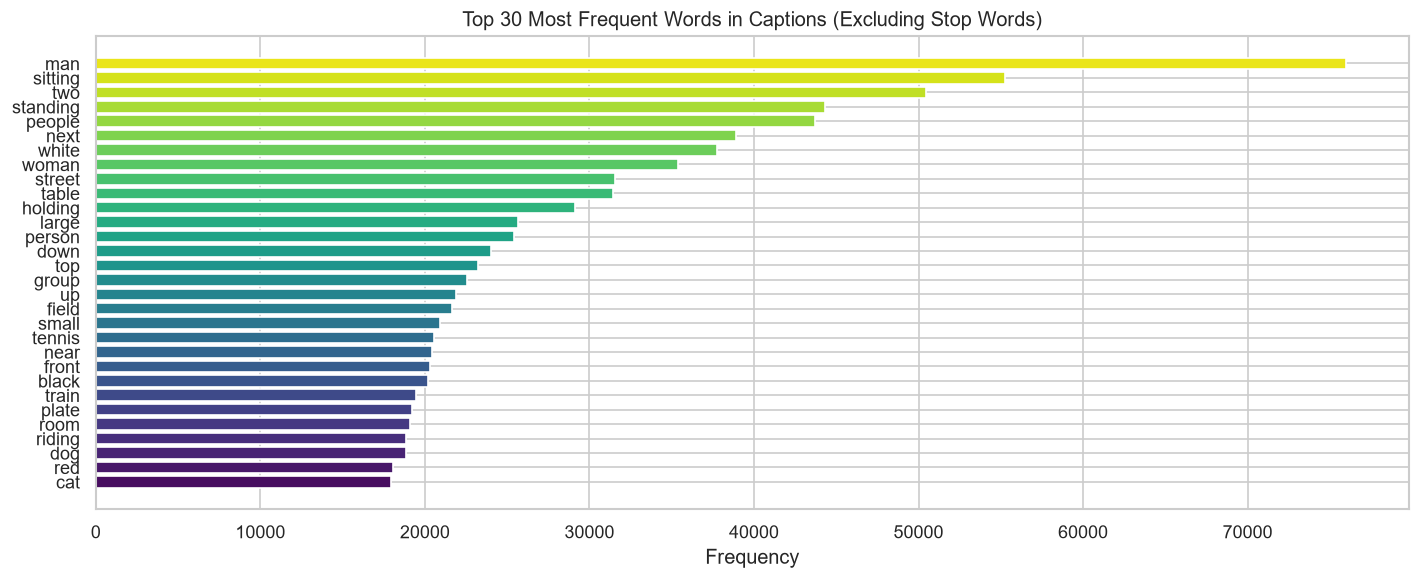

In [38]:
STOPWORDS = {
    "a", "an", "the", "of", "in", "is", "on", "with", "and",
    "are", "to", "at", "it", "its", "by", "for", "that",
    "this", "has", "have", "from", "be", "as", "there",
    "some", "each", "into", "was", "his", "her", "their",
}

all_words = []
for cap in captions:
    tokens = re.findall(r"[a-z]+", cap.lower())
    all_words.extend(t for t in tokens if t not in STOPWORDS)

top_words = Counter(all_words).most_common(30)
words, freqs = zip(*top_words, strict=False)

plt.figure(figsize=(12, 5))
palette = sns.color_palette("viridis", len(words))
plt.barh(words[::-1], freqs[::-1], color=palette)
plt.xlabel("Frequency")
plt.title("Top 30 Most Frequent Words in Captions (Excluding Stop Words)")
plt.tight_layout()
plt.show()

## Audio statistics

In [82]:
wav_files = (
    list(Path(PATH_WAVS_TRAIN).rglob("*.wav"))
    #+ list(Path(PATH_WAVS_VAL).rglob("*.wav"))
)[:100000]

records = []
for f in tqdm(wav_files, desc="Reading WAV headers"):
    try:
        with wave.open(str(f), "rb") as wav:
            frames = wav.getnframes()
            rate = wav.getframerate()

            records.append({
                "file": f.name,
                "duration_s": frames / rate,
                "sample_rate_hz": rate,
                "channels": wav.getnchannels(),
                "frames": frames,
                "sample_width_bytes": wav.getsampwidth()
            })
    except (wave.Error, OSError, EOFError) as e:
        print(f"Could not read {f}: {e}")

wavs_df = pd.DataFrame(records)
wavs_df.to_csv("../data/wavs_metadata_train.csv", index=False)

print(f"\nSuccessfully analyzed: {len(wavs_df)}")

Reading WAV headers: 100%|██████████| 100000/100000 [00:03<00:00, 28443.12it/s]



Successfully analyzed: 100000


## Integrity of audio

In [83]:
durations = wavs_df["duration_s"]

print("AUDIO DATA QUALITY CHECK")
print("-" * 40)

print("Empty recordings:", (wavs_df["frames"] == 0).sum())
print("Duration <= 0:", (wavs_df["duration_s"] <= 0).sum())
print("Different sampling rates:",
      wavs_df["sample_rate_hz"].nunique())
print("Different channel configurations:",
      wavs_df["channels"].nunique())

print("\nDuration covered by all recordings:",
      f"{durations.sum() / 3600:.2f} hours")

AUDIO DATA QUALITY CHECK
----------------------------------------
Empty recordings: 0
Duration <= 0: 0
Different sampling rates: 1
Different channel configurations: 1

Duration covered by all recordings: 117.39 hours


## Audio duration distribution

In [84]:
p99 = durations.quantile(0.99)
p995 = durations.quantile(0.995)

print("AUDIO DURATION STATISTICS")
print("-" * 40)
print(f"Count:           {len(durations)}")
print(f"Mean:            {durations.mean():.4f} s")
print(f"Median:          {durations.median():.4f} s")
print(f"Standard dev.:   {durations.std():.4f} s")
print(f"Minimum:         {durations.min():.4f} s")
print(f"Maximum:         {durations.max():.4f} s")
print(f"90th percentile: {durations.quantile(0.90):.4f} s")
print(f"95th percentile: {durations.quantile(0.95):.4f} s")
print(f"99th percentile: {p99:.4f} s")
print(f"99.5th percentile: {p995:.4f} s")

print(f"\nAt most {p99:.4f} s covers approximately 99% of recordings.")
print(f"At most {p995:.4f} s covers approximately 99.5% of recordings.")

AUDIO DURATION STATISTICS
----------------------------------------
Count:           100000
Mean:            4.2259 s
Median:          4.0107 s
Standard dev.:   1.3968 s
Minimum:         1.1947 s
Maximum:         39.5947 s
90th percentile: 5.8880 s
95th percentile: 6.6560 s
99th percentile: 8.6385 s
99.5th percentile: 9.8133 s

At most 8.6385 s covers approximately 99% of recordings.
At most 9.8133 s covers approximately 99.5% of recordings.


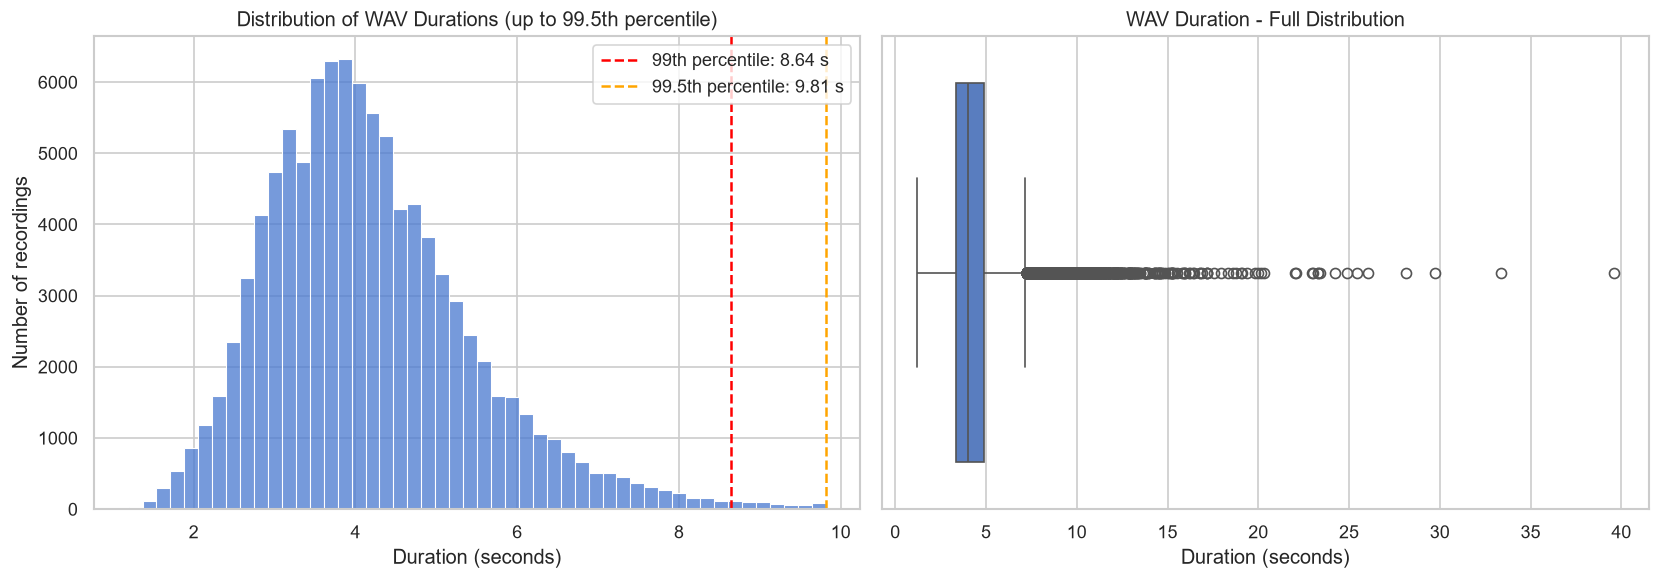

In [85]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(
    durations[durations <= p995],
    bins=50,
    ax=axes[0]
)
axes[0].axvline(p99, color="red", linestyle="--",
                label=f"99th percentile: {p99:.2f} s")
axes[0].axvline(p995, color="orange", linestyle="--",
                label=f"99.5th percentile: {p995:.2f} s")
axes[0].set_title("Distribution of WAV Durations (up to 99.5th percentile)")
axes[0].set_xlabel("Duration (seconds)")
axes[0].set_ylabel("Number of recordings")
axes[0].legend()

sns.boxplot(x=durations, ax=axes[1])
axes[1].set_title("WAV Duration - Full Distribution")
axes[1].set_xlabel("Duration (seconds)")

plt.tight_layout()
plt.show()

## Other audio statistics

SAMPLING RATE DISTRIBUTION
sample_rate_hz
16000    100000
Name: count, dtype: int64

CHANNEL DISTRIBUTION
channels
1    100000
Name: count, dtype: int64

AUDIO BIT DEPTH
sample_width_bytes
16    100000
Name: count, dtype: int64

NUMBER OF FRAMES
count    100000.00
mean      67614.50
std       22348.59
min       19115.00
25%       53248.00
50%       64171.00
75%       77824.00
max      633515.00
Name: frames, dtype: float64

All recordings have the same sampling rate: True


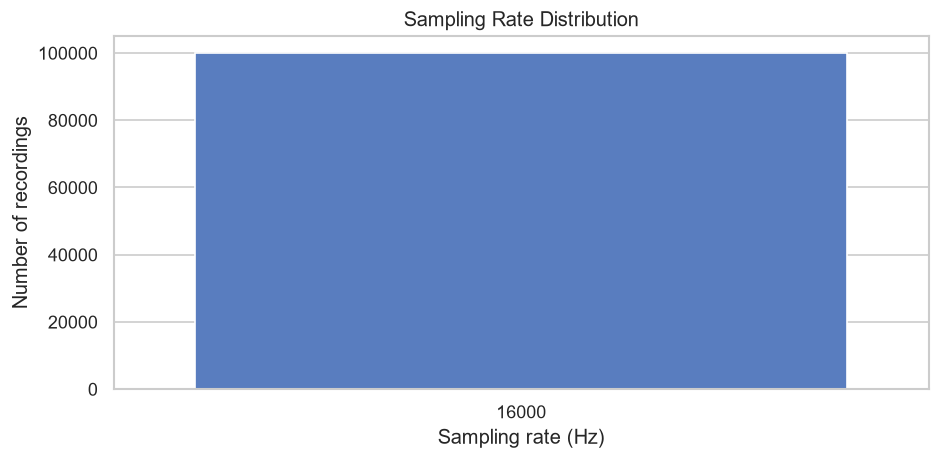

In [86]:
print("SAMPLING RATE DISTRIBUTION")
print(wavs_df["sample_rate_hz"].value_counts().sort_index())

print("\nCHANNEL DISTRIBUTION")
print(wavs_df["channels"].value_counts().sort_index())

print("\nAUDIO BIT DEPTH")
print((wavs_df["sample_width_bytes"] * 8).value_counts().sort_index())

print("\nNUMBER OF FRAMES")
print(wavs_df["frames"].describe().round(2))

unique_rates = wavs_df["sample_rate_hz"].unique()
print("\nAll recordings have the same sampling rate:",
      len(unique_rates) == 1)

plt.figure(figsize=(8, 4))
rate_counts = wavs_df["sample_rate_hz"].value_counts().sort_index()
sns.barplot(x=rate_counts.index.astype(str), y=rate_counts.values)
plt.title("Sampling Rate Distribution")
plt.xlabel("Sampling rate (Hz)")
plt.ylabel("Number of recordings")
plt.tight_layout()
plt.show()

## Example images with text and sound captions


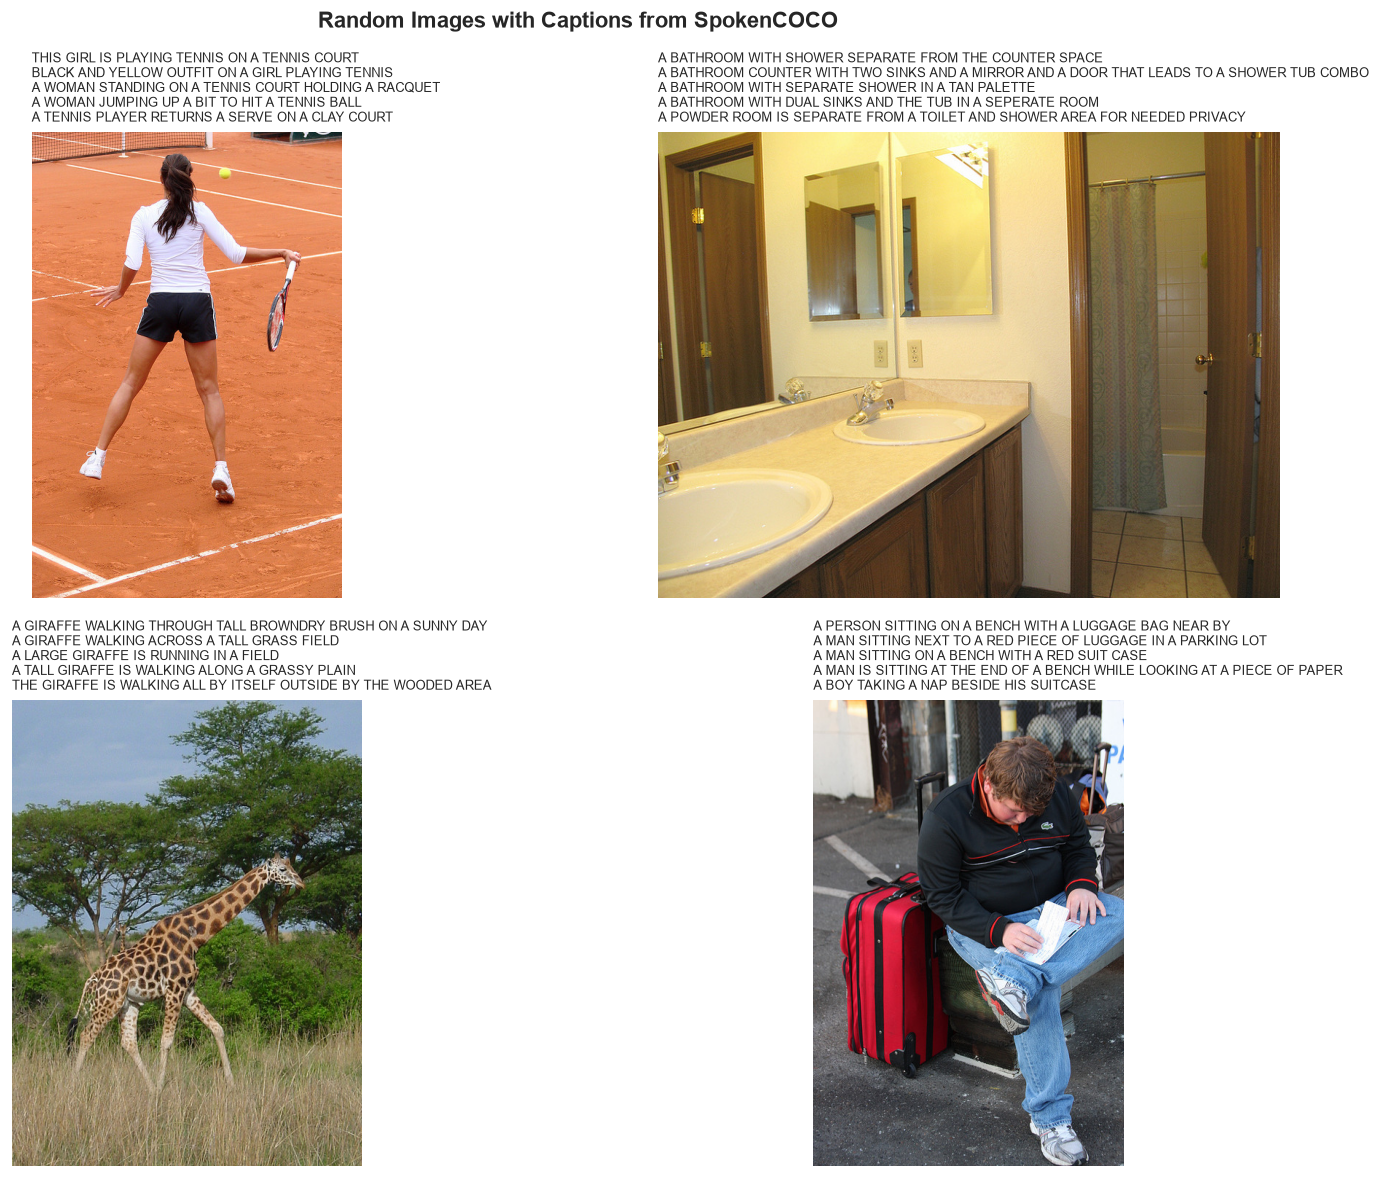


Image: COCO_train2014_000000515392.jpg
Caption: THIS GIRL IS PLAYING TENNIS ON A TENNIS COURT



Image: COCO_train2014_000000294371.jpg
Caption: A BATHROOM WITH DUAL SINKS AND THE TUB IN A SEPERATE ROOM



Image: COCO_train2014_000000368253.jpg
Caption: A LARGE GIRAFFE IS RUNNING IN A FIELD



Image: COCO_val2014_000000424246.jpg
Caption: A MAN SITTING ON A BENCH WITH A RED SUIT CASE


In [71]:
random.seed(124)

fig, axes = plt.subplots(2, 2, figsize=(15, 10))
axes = axes.flatten()

random_4_image_ids = random.sample(list(id_to_file.keys()), 4)

for i, img_id in enumerate(random_4_image_ids):
    image_path = id_to_file[img_id]

    if image_path.startswith("train2014/"):
        full_path = os.path.join(PATH_IMAGES_TRAIN, os.path.basename(image_path))
    else:
        full_path = os.path.join(PATH_IMAGES_VAL, os.path.basename(image_path))

    image = Image.open(full_path)
    axes[i].imshow(image)
    axes[i].axis("off")
    axes[i].set_title("\n".join(annotation_dict[img_id]), fontsize=8, loc="left")

plt.suptitle("Random Images with Captions from SpokenCOCO", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

for img_id in random_4_image_ids:
    item = next(
        item
        for dataset in (train_data, val_data)
        for item in dataset["data"]
        if os.path.basename(item["image"]) == img_id
    )

    caption = random.choice(item["captions"])
    wav_path = Path(caption["wav"])

    relative_path = Path(*wav_path.parts[2:])
    candidates = [
        Path(PATH_WAVS_TRAIN) / relative_path,
        Path(PATH_WAVS_VAL) / relative_path
    ]
    audio_path = next((p for p in candidates if p.is_file()), None)

    print(f"\nImage: {img_id}")
    print(f"Caption: {caption['text']}")

    if audio_path:
        display(Audio(filename=str(audio_path)))
    else:
        print(f"Audio not found: {caption['wav']}")

## Mean and std of image pixels

In [87]:
train_image_paths = [
    os.path.join(PATH_IMAGES_TRAIN, fname)
    for fname in os.listdir(PATH_IMAGES_TRAIN)
    if fname.lower().endswith((".jpg", ".jpeg", ".png"))
]

sample_size = 5000
rng = np.random.default_rng(42)
sample_paths = rng.choice(
    train_image_paths,
    min(sample_size, len(train_image_paths)),
    replace=False
)

mean_acc = np.zeros(3)
squared_acc = np.zeros(3)
pixel_count = 0

for path in tqdm(sample_paths, desc="Calculating statistics"):
    with Image.open(path) as img:
        arr = np.array(img.convert("RGB"), dtype=np.float32) / 255.0

    pixels = arr.reshape(-1, 3)
    mean_acc += pixels.sum(axis=0)
    squared_acc += (pixels ** 2).sum(axis=0)
    pixel_count += len(pixels)

pixel_mean = mean_acc / pixel_count
pixel_std = np.sqrt(squared_acc / pixel_count - pixel_mean ** 2)

print(f"Mean (R, G, B): {pixel_mean}")
print(f"Std (R, G, B): {pixel_std}")

Calculating statistics: 100%|██████████| 5000/5000 [00:33<00:00, 147.73it/s]

Mean (R, G, B): [0.47116698 0.44670493 0.40732929]
Std (R, G, B): [0.27892825 0.27424563 0.28907873]


## Pixel value distribution

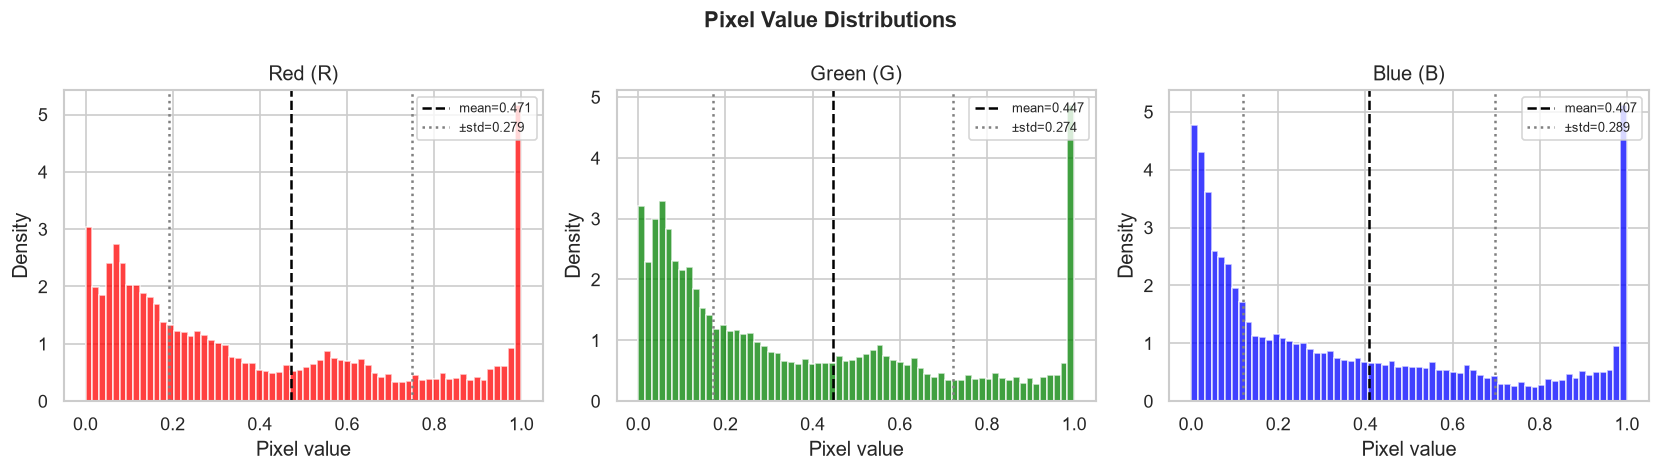

In [73]:
sample_img_path = sample_paths[0]
sample_arr = np.array(Image.open(sample_img_path).convert("RGB")) / 255.0

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
fig.suptitle("Pixel Value Distributions", fontsize=13, fontweight="bold")

channel_names = ["Red (R)", "Green (G)", "Blue (B)"]
colors = ["red", "green", "blue"]

for c, (ax, name, col) in enumerate(
    zip(axes, channel_names, colors, strict=False)
):
    ax.hist(
        sample_arr[:, :, c].ravel(),
        bins=64,
        color=col,
        alpha=0.75,
        density=True,
    )
    ax.axvline(
        pixel_mean[c],
        color="black",
        linestyle="--",
        label=f"mean={pixel_mean[c]:.3f}",
    )
    ax.axvline(
        pixel_mean[c] + pixel_std[c],
        color="gray",
        linestyle=":",
        label=f"±std={pixel_std[c]:.3f}",
    )
    ax.axvline(
        pixel_mean[c] - pixel_std[c],
        color="gray",
        linestyle=":",
    )
    ax.set_title(name)
    ax.set_xlabel("Pixel value")
    ax.set_ylabel("Density")
    ax.legend(fontsize=8)

plt.tight_layout()
plt.show()

## Transforms visualization


Image: COCO_train2014_000000515392.jpg
Original tensor shape: torch.Size([3, 640, 426])
After TrainTransform: torch.Size([3, 224, 224])


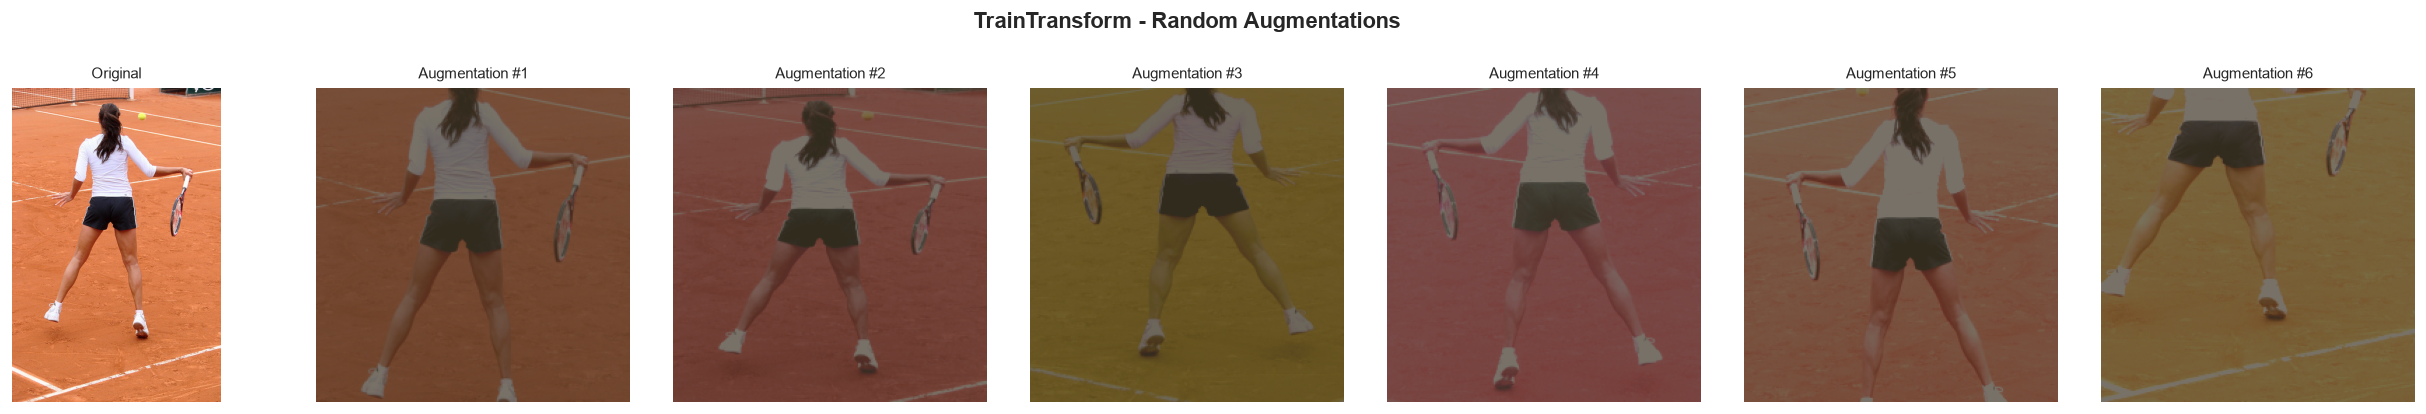

In [97]:
random.seed(124)
np.random.seed(124)
torch.manual_seed(124)

sys.path.append("../torch_datasets")
from transforms import Img_TrainTransform  # type: ignore # noqa: E402

TRAIN_MEAN = [0.47116698, 0.44670493, 0.40732929]
TRAIN_STD = [0.27892825, 0.27424563, 0.28907873]

def denormalize(tensor: torch.Tensor) -> np.ndarray:
    mean = torch.tensor(TRAIN_MEAN).view(3, 1, 1)
    std = torch.tensor(TRAIN_STD).view(3, 1, 1)

    return (
        (tensor * std + mean)
        .clamp(0, 1)
        .permute(1, 2, 0)
        .numpy()
    )

sample_item = random.choice(train_data["data"])
image_path = sample_item["image"]
image_name = os.path.basename(image_path)

if image_path.startswith("train2014/"):
    sample_img_path = os.path.join(PATH_IMAGES_TRAIN, image_name)
else:
    sample_img_path = os.path.join(PATH_IMAGES_VAL, image_name)

sample_pil = Image.open(sample_img_path).convert("RGB")
sample_tensor = ToTensor()(sample_pil)

train_transform = Img_TrainTransform()
out_train = train_transform(sample_tensor.clone())

print(f"Image: {image_name}")
print(f"Original tensor shape: {sample_tensor.shape}")
print(f"After TrainTransform: {out_train.shape}")

N = 6
fig, axes = plt.subplots(1, N + 1, figsize=((N + 1) * 3, 3.5))
fig.suptitle("TrainTransform - Random Augmentations",
             fontsize=13, fontweight="bold")

axes[0].imshow(sample_tensor.permute(1, 2, 0).numpy())
axes[0].set_title("Original", fontsize=9)
axes[0].axis("off")

for k, ax in enumerate(axes[1:], 1):
    augmented = train_transform(sample_tensor.clone())
    ax.imshow(denormalize(augmented))
    ax.set_title(f"Augmentation #{k}", fontsize=9)
    ax.axis("off")

plt.tight_layout()
plt.show()